# QLBS walkthrough: pricing and hedging a European put with Q-learning

This notebook walks through the model on the base case ($S_0=K=100$, $\mu=5\%$, $r=3\%$, $\sigma=15\%$, $T=1$, 6 rebalancing dates). The reusable code lives in `src/qlbs/`; the full experiments are in `scripts/run_experiments.py`.

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, matplotlib.pyplot as plt
from qlbs import Market, Simulation, solve_dp, solve_fqi, off_policy_data, bs_price, mc_price
m = Market(s0=100, strike=100, mu=0.05, sigma=0.15, r=0.03, T=1.0)
sim = Simulation(m, steps=6, paths=10_000, seed=42)

## 1. State and dynamics
Stock paths follow geometric Brownian motion under the real-world measure, $S_{t+1}=S_t\,e^{(\mu-\sigma^2/2)\Delta t+\sigma\sqrt{\Delta t}Z}$.
The state is the drift-adjusted log price $X_t=\log S_t-(\mu-\sigma^2/2)\,t\Delta t$, expanded in 12 degree-4 B-spline features $\Phi_n(X_t)$. The excess stock move is $\Delta S_t=S_{t+1}-e^{r\Delta t}S_t$.

## 2. Dynamic programming solution
The hedge portfolio is rolled back from the payoff, $\Pi_T=H(S_T)$, $\Pi_t=\gamma(\Pi_{t+1}-a_t\Delta S_t)$, with $\gamma=e^{-r\Delta t}$. The hedge minimises the conditional variance of $\Pi_t$, fitted by ridge regression on the features:

$$a_t^\star(X_t)=\sum_n\phi_{nt}\Phi_n(X_t),\qquad \phi_t=\mathbf A_t^{-1}\mathbf B_t,\quad A^{(t)}_{nm}=\sum_k\Phi_n\Phi_m(\Delta\hat S^k_t)^2,\quad B^{(t)}_n=\sum_k\Phi_n\hat\Pi^k_{t+1}\Delta\hat S^k_t$$

The one-step reward is $R_t=\gamma a_t\Delta S_t-\lambda\,\mathrm{Var}[\Pi_t]$, and the optimal Q-function satisfies the Bellman equation $Q_t^\star=\mathbb E_t[R_t+\gamma Q_{t+1}^\star]$, with $Q_T^\star=-\Pi_T-\lambda\mathrm{Var}[\Pi_T]$. The QLBS price is $-Q_0^\star$.

In [2]:
dp = solve_dp(sim, "put", risk_lambda=0.001)
bs = float(bs_price(m.s0, m.strike, m.r, m.sigma, m.T, "put"))
mc, se = mc_price(m.s0, m.strike, m.r, m.sigma, m.T, "put")
print(f"QLBS (DP)        {dp.price:.4f}")
print(f"Black-Scholes    {bs:.4f}")
print(f"Monte Carlo (RN) {mc:.4f} ± {se:.4f}")

QLBS (DP)        4.6598
Black-Scholes    4.5296
Monte Carlo (RN) 4.5351 ± 0.0156


## 3. Model-free Q-learning (fitted Q iteration)
Now forget the model: the learner only sees *off-policy* data, trajectories generated with noisy hedges $a_t=a_t^\star\cdot U[1-\eta,1+\eta]$ ($\eta=0.5$) and the rewards they earned. The Q-function is quadratic in the action,

$$Q_t(x,a)=\mathbf W_t\cdot\Psi(x,a),\qquad \Psi(x,a)=\left(1,\ a,\ \tfrac12a^2\right)\otimes\Phi(x),$$

and $\mathbf W_t$ is fitted backward in time by least squares on the Bellman targets $R_t+\gamma Q_{t+1}(X_{t+1},a^\star_{t+1})$.

QLBS (Q-learning, off-policy) 4.6971


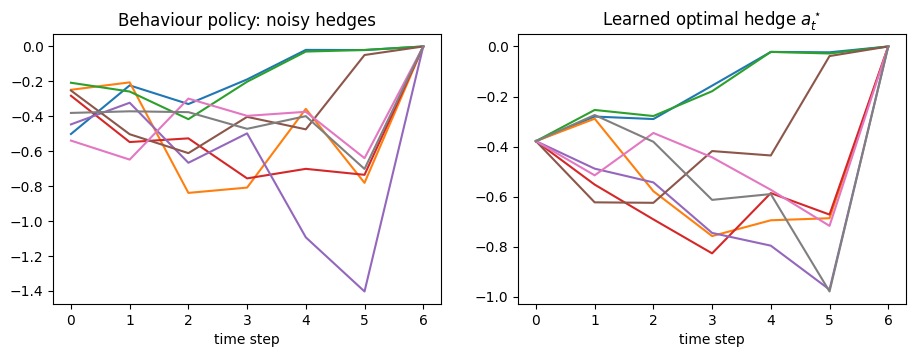

In [3]:
a, pi, R = off_policy_data(sim, dp.hedge, "put", risk_lambda=0.001, eta=0.5, seed=42)
fqi = solve_fqi(sim, a, pi, R, risk_lambda=0.001)
print(f"QLBS (Q-learning, off-policy) {fqi.price:.4f}")

idx = np.linspace(0, sim.paths - 1, 8, dtype=int)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(a[idx].T); ax[0].set_title("Behaviour policy: noisy hedges")
ax[1].plot(fqi.hedge[idx].T); ax[1].set_title("Learned optimal hedge $a_t^\star$")
for x in ax: x.set_xlabel("time step")
plt.show()

## 4. Experiments
`scripts/run_experiments.py` runs the volatility, rebalancing, risk-aversion and convergence studies. Their figures:

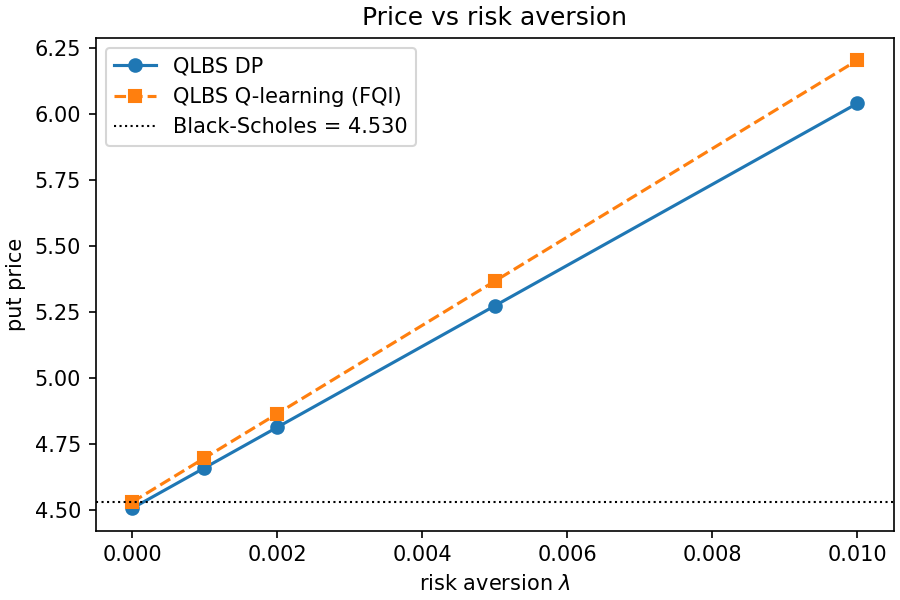

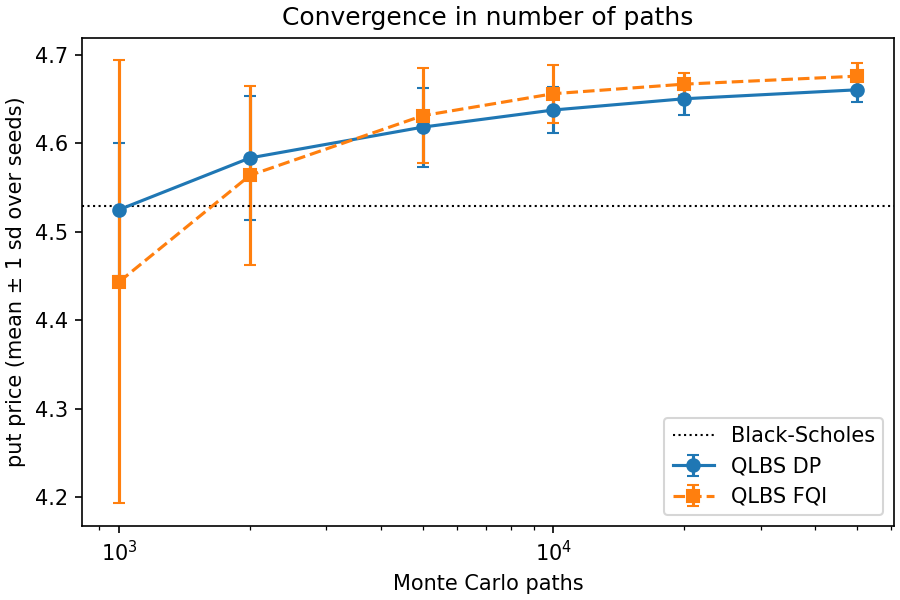

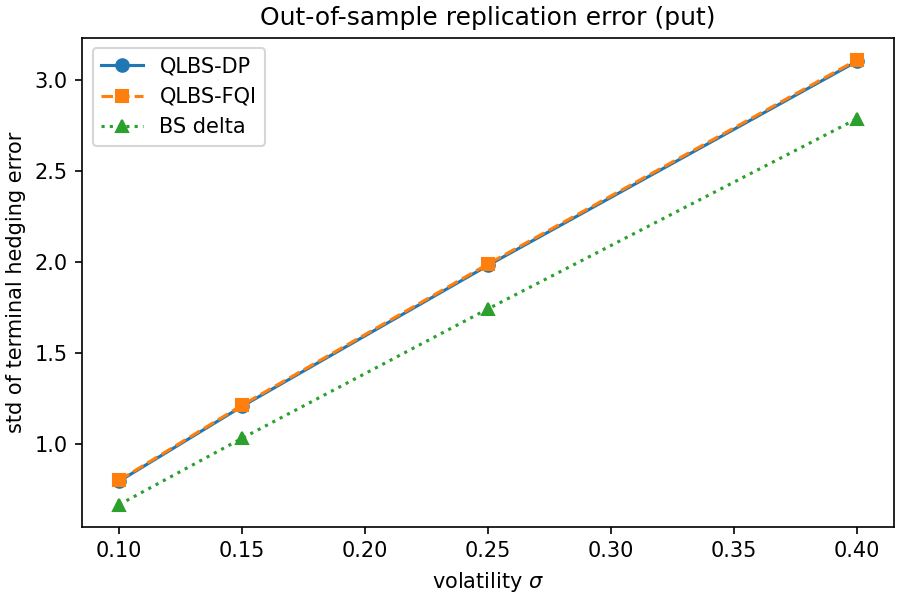

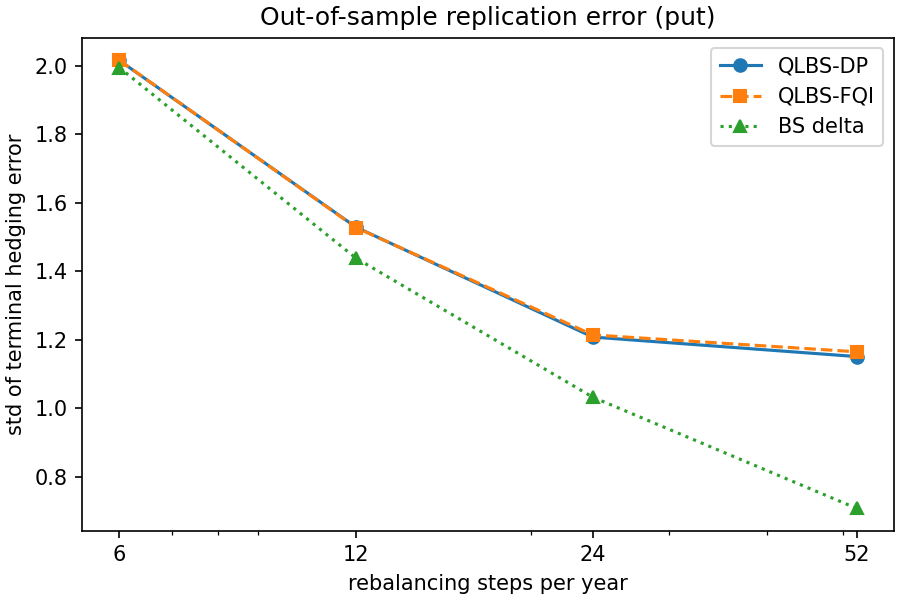

In [4]:
from IPython.display import Image, display
for f in ["price_vs_lambda", "convergence", "hedge_error_vs_volatility", "hedge_error_vs_rebalancing"]:
    display(Image(f"../results/{f}.png"))